# Tier 2 ASR analysis – M3AV (300‑clip run)
Reads `tier2_m3av_results.csv` produced from the Tier 2 batch runs and summarizes WER/CER vs DSP condition and duration bucket.


## Note: B/C/D equivalence

hp, hp+sg, hp_wiener are the same high-pass-only chain in _condition_config (backend/app/eval_runner.py:372-381); stored effective_config shows spectral_gating_enabled=false and evaluation_arm="". Differences on identical audio across B/C/D are ASR decode nondeterminism (see noise-floor cell below), not DSP.


In [10]:

import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

BASE = Path(r"C:\Users\Leon\Documents\Github\finalproject_cpe027\kaggle\results")
df = pd.read_csv(BASE / "tier2_m3av_results.csv")
df["WER_pct"] = 100 * df["wer"]
df["CER_pct"] = 100 * df["cer"]
df["duration_min"] = df["audio_duration_s"] / 60.0
print("records:", len(df), "clips:", df["clip_id"].nunique(), "conditions:", df["condition"].nunique())
df.head()


records: 1800 clips: 300 conditions: 6


,tier,clip_id,duration_bucket,condition,wer,cer,kter,term_presence_recall,terms_present,nshr,rtf,audio_duration_s,seconds,language,WER_pct,CER_pct,duration_min
0,2,CHI-003EC,5-10m,arm_a,0.275456,0.164962,NaN,NaN,0,0.0,0.067762,304.23,20.615194,en,27.545552,16.496212,5.0705
1,2,CHI-003EC,5-10m,hp,0.294748,0.163068,NaN,NaN,0,0.0,0.095483,304.23,29.048884,en,29.474812,16.306818,5.0705
2,2,CHI-003EC,5-10m,hp+sg,0.294748,0.163068,NaN,NaN,0,0.0,0.095209,304.23,28.965446,en,29.474812,16.306818,5.0705
3,2,CHI-003EC,5-10m,hp_ffmpeg,0.306538,0.180492,NaN,NaN,0,0.0,0.093229,304.23,28.363000,en,30.653805,18.049242,5.0705
4,2,CHI-003EC,5-10m,hp_wiener,0.294748,0.163068,NaN,NaN,0,0.0,0.095493,304.23,29.051776,en,29.474812,16.306818,5.0705


## Overall per condition

In [11]:

overall = (
    df.groupby("condition", dropna=False)
    .agg(n=("clip_id", "count"),
         duration_m=("duration_min", "mean"),
         WER_pct=("WER_pct", "mean"),
         CER_pct=("CER_pct", "mean"),
         term_presence=("term_presence_recall", "mean"),
         NSHR=("nshr", "mean"),
         RTF=("rtf", "mean"),
         seconds=("seconds", "mean"))
    .round(3)
    .sort_index()
)
overall


,n,duration_m,WER_pct,CER_pct,term_presence,NSHR,RTF,seconds
condition,,,,,,,,
arm_a,300,4.961,7.514,3.225,NaN,0.0,0.064,19.072
hp,300,4.961,7.509,3.220,NaN,0.0,0.092,27.502
hp+sg,300,4.961,7.509,3.220,NaN,0.0,0.092,27.503
hp_ffmpeg,300,4.961,8.275,3.624,NaN,0.0,0.090,26.644
hp_wiener,300,4.961,7.509,3.221,NaN,0.0,0.093,27.518
hp_wiener_oa,300,4.961,7.638,3.291,NaN,0.0,0.091,26.927


## WER / CER by duration bucket × condition

In [12]:

bucket = (
    df.groupby(["duration_bucket", "condition"], dropna=False)
    .agg(n=("clip_id", "count"),
         WER_pct=("WER_pct", "mean"),
         CER_pct=("CER_pct", "mean"),
         NSHR=("nshr", "mean"),
         RTF=("rtf", "mean"),
         seconds=("seconds", "mean"))
    .round(3)
)
bucket


n  WER_pct  CER_pct   NSHR    RTF  seconds
duration_bucket condition                                                 
5-10m           arm_a         160    7.487    3.215  0.000  0.064   19.605
                hp            160    7.501    3.198  0.000  0.092   28.217
                hp+sg         160    7.501    3.200  0.000  0.092   28.230
                hp_ffmpeg     160    8.267    3.616  0.000  0.089   27.336
                hp_wiener     160    7.501    3.201  0.000  0.092   28.243
                hp_wiener_oa  160    7.583    3.244  0.000  0.090   27.668
<5m             arm_a         140    7.544    3.236  0.000  0.064   18.462
                hp            140    7.520    3.244  0.000  0.093   26.685
                hp+sg         140    7.518    3.243  0.000  0.093   26.672
                hp_ffmpeg     140    8.284    3.633  0.000  0.090   25.855
                hp_wiener     140    7.520    3.244  0.000  0.093   26.690
                hp_wiener_oa  140    7.701    3.344  0.001  0.091   26.080

## Relative WER change vs arm_a within each bucket

In [13]:

rows = []
for bkt, sub in df.groupby("duration_bucket"):
    base = sub.loc[sub["condition"] == "arm_a", "wer"].mean()
    for c, grp in sub.groupby("condition"):
        gain = (grp["wer"].mean() - base) / base * 100.0 if (base and base > 0) else float("nan")
        rows.append({
            "duration_bucket": bkt,
            "condition": c,
            "n": len(grp),
            "mean_wer_pct": round(100 * grp["wer"].mean(), 2),
            "arm_a_wer_pct": round(100 * base, 2),
            "rel_change_vs_arm_a_pct": round(gain, 2),
        })
relative = pd.DataFrame(rows).set_index(["duration_bucket", "condition"]).sort_index()
relative


n  mean_wer_pct  arm_a_wer_pct  \
duration_bucket condition                                        
5-10m           arm_a         160          7.49           7.49   
                hp            160          7.50           7.49   
                hp+sg         160          7.50           7.49   
                hp_ffmpeg     160          8.27           7.49   
                hp_wiener     160          7.50           7.49   
                hp_wiener_oa  160          7.58           7.49   
<5m             arm_a         140          7.54           7.54   
                hp            140          7.52           7.54   
                hp+sg         140          7.52           7.54   
                hp_ffmpeg     140          8.28           7.54   
                hp_wiener     140          7.52           7.54   
                hp_wiener_oa  140          7.70           7.54   

                              rel_change_vs_arm_a_pct  
duration_bucket condition                              
5-10m           arm_a                            0.00  
                hp                               0.18  
                hp+sg                            0.19  
                hp_ffmpeg                       10.41  
                hp_wiener                        0.18  
                hp_wiener_oa                     1.28  
<5m             arm_a                            0.00  
                hp                              -0.33  
                hp+sg                           -0.35  
                hp_ffmpeg                        9.81  
                hp_wiener                       -0.33  
                hp_wiener_oa                     2.08

## Figure 1 – mean WER by condition

In [14]:

means = df.groupby("condition", sort=True)["wer"].mean().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(means.index, 100 * means.values, color="#4c78a8")
ax.set_title("Tier 2 mean WER by DSP condition (300 clips)")
ax.set_ylabel("WER (%)")
ax.set_xticks(range(len(means.index)))
ax.set_xticklabels(means.index, rotation=30, ha="right")
fig.tight_layout()
fig.savefig(BASE / "tier2_wer_by_condition.png", dpi=150)
plt.close(fig)
plt.show()


## Figure 2 – WER by duration bucket × condition

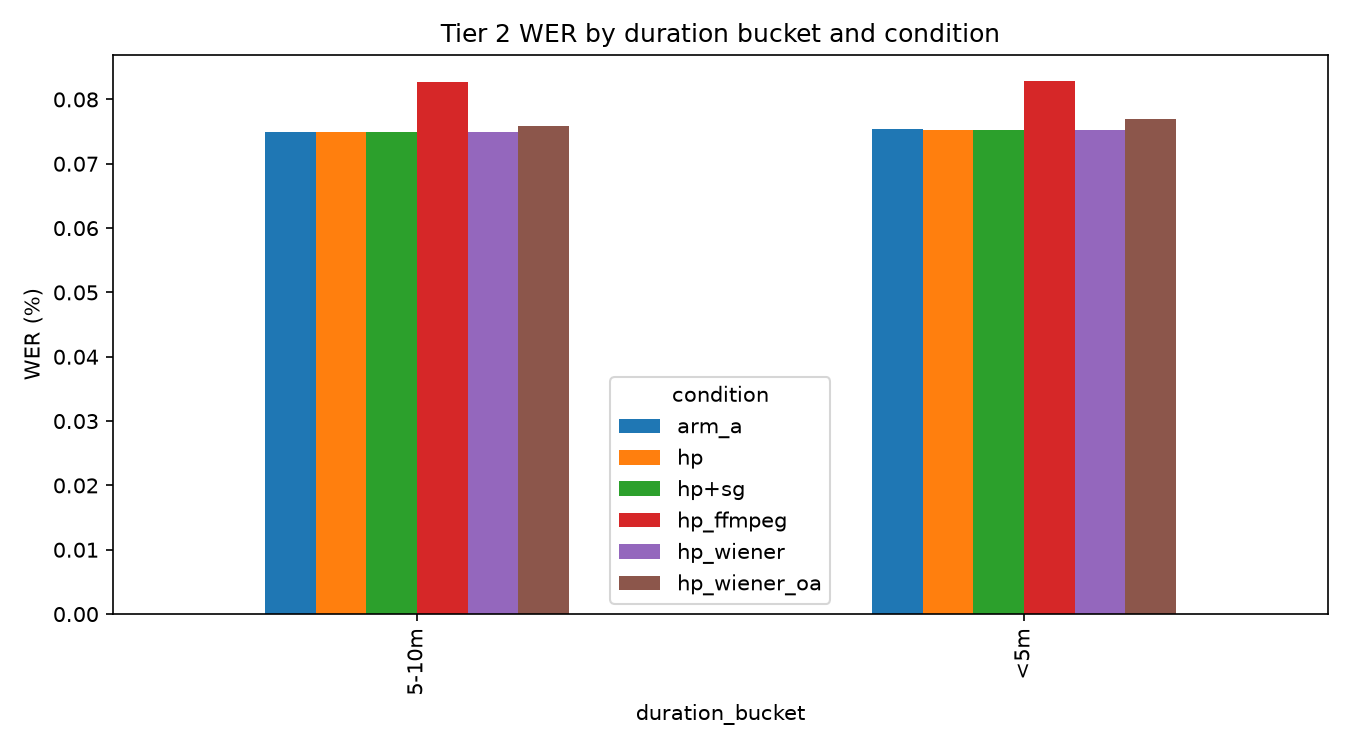

In [15]:

bybucket = df.groupby(["duration_bucket", "condition"], sort=True)["wer"].mean().unstack("condition")
fig, ax = plt.subplots(figsize=(9, 5))
bybucket.plot.bar(ax=ax)
ax.set_title("Tier 2 WER by duration bucket and condition")
ax.set_ylabel("WER (%)")
fig.tight_layout()
fig.savefig(BASE / "tier2_wer_by_bucket.png", dpi=150)
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(BASE / "tier2_wer_by_bucket.png"), width=900))


## Figure 3 – relative WER gain vs arm_a by duration bucket

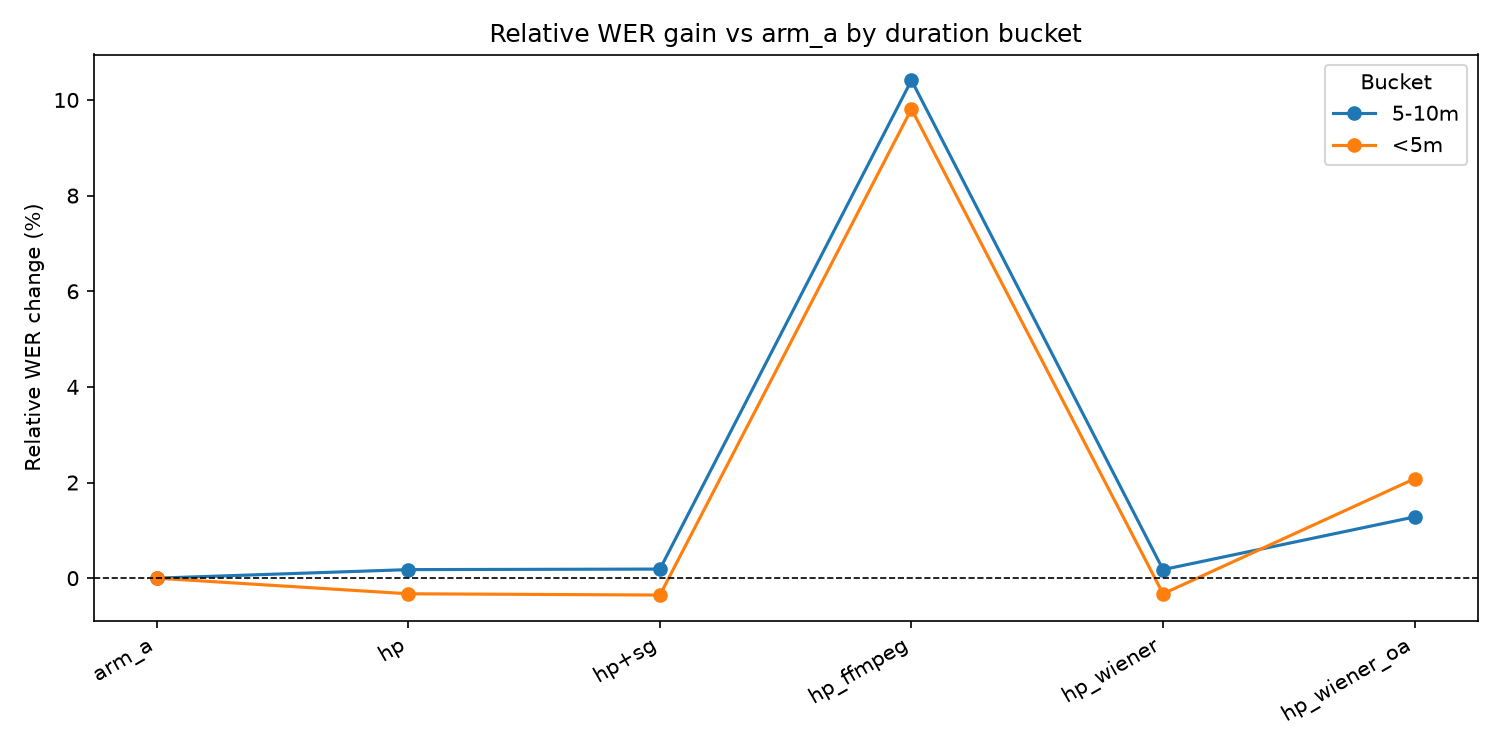

In [16]:

fig, ax = plt.subplots(figsize=(10, 5))
for bkt, sub in df.groupby("duration_bucket"):
    arm_a = sub.loc[sub["condition"] == "arm_a", "wer"].mean()
    gain = (sub.groupby("condition", sort=True)["wer"].mean() - arm_a) / arm_a * 100.0
    ax.plot(gain.index, gain.values, marker="o", label=bkt)
ax.axhline(0, color="k", linewidth=0.8, linestyle="--")
ax.set_title("Relative WER gain vs arm_a by duration bucket")
ax.set_ylabel("Relative WER change (%)")
ax.set_xticks(range(len(gain.index)))
ax.set_xticklabels(gain.index, rotation=30, ha="right")
ax.legend(title="Bucket")
fig.tight_layout()
fig.savefig(BASE / "tier2_rel_wer_vs_arm_a.png", dpi=150)
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(BASE / "tier2_rel_wer_vs_arm_a.png"), width=900))


## Extremes (clips, 2 each)

In [17]:

worst = (df.sort_values("wer", ascending=False)
        .groupby("condition", dropna=False)
        .head(2)[["clip_id", "condition", "audio_duration_s", "wer", "cer", "nshr"]])
best = (df.sort_values("wer", ascending=True)
        .groupby("condition", dropna=False)
        .head(2)[["clip_id", "condition", "audio_duration_s", "wer", "cer", "nshr"]])
print("Worst (hardest clips):")
display(worst.round(3))
print("\nBest (easiest clips):")
display(best.round(3))


Worst (hardest clips):


,clip_id,condition,audio_duration_s,wer,cer,nshr
513,CHI-34A79,hp_ffmpeg,304.02,0.434,0.224,0.0
183,CHI-1366D,hp_ffmpeg,323.45,0.405,0.205,0.0
510,CHI-34A79,arm_a,304.02,0.364,0.189,0.0
515,CHI-34A79,hp_wiener_oa,304.02,0.348,0.184,0.0
512,CHI-34A79,hp+sg,304.02,0.340,0.177,0.0
514,CHI-34A79,hp_wiener,304.02,0.338,0.177,0.0
511,CHI-34A79,hp,304.02,0.338,0.175,0.0
185,CHI-1366D,hp_wiener_oa,323.45,0.330,0.161,0.0
180,CHI-1366D,arm_a,323.45,0.320,0.161,0.0
182,CHI-1366D,hp+sg,323.45,0.316,0.152,0.0



Best (easiest clips):


,clip_id,condition,audio_duration_s,wer,cer,nshr
983,CHI-03E0E,hp_wiener_oa,297.44,0.005,0.002,0.0
978,CHI-03E0E,arm_a,297.44,0.008,0.002,0.0
321,CHI-2430D,hp_ffmpeg,303.82,0.009,0.003,0.0
318,CHI-2430D,arm_a,303.82,0.010,0.005,0.0
1412,CHI-3C616,hp+sg,278.32,0.010,0.005,0.0
1411,CHI-3C616,hp,278.32,0.010,0.005,0.0
1414,CHI-3C616,hp_wiener,278.32,0.010,0.005,0.0
1223,CHI-2483D,hp_wiener_oa,279.65,0.011,0.005,0.0
980,CHI-03E0E,hp+sg,297.44,0.011,0.003,0.0
979,CHI-03E0E,hp,297.44,0.011,0.003,0.0


## Save tables

In [18]:

overall.reset_index().to_csv(BASE / "tier2_overall_by_condition.csv", index=False)
bucket.reset_index().to_csv(BASE / "tier2_wer_by_bucket.csv", index=False)
relative.reset_index().to_csv(BASE / "tier2_rel_wer_vs_arm_a.csv", index=False)
print("Saved overall/bucket/relative CSV tables.")


Saved overall/bucket/relative CSV tables.


In [19]:
# Build a derived condition table: merge hp/hp+sg/hp_wiener into one "high_pass" arm.
import json
from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Leon\Documents\Github\finalproject_cpe027\kaggle\results")
DERIVED_DIR = BASE / "derived"
DERIVED_DIR.mkdir(parents=True, exist_ok=True)
OUT = DERIVED_DIR / "tier2_merged_conditions.csv"

df = pd.read_csv(BASE / "tier2_m3av_results.csv")
merge_set = {"hp", "hp+sg", "hp_wiener"}

merged = (
    df[df["condition"].isin(merge_set)]
    .assign(condition="high_pass")
    .groupby(["clip_id", "duration_bucket", "condition"], dropna=False, as_index=False)
    .agg(
        wer=("wer", "mean"),
        cer=("cer", "mean"),
        wer_min=("wer", "min"),
        wer_max=("wer", "max"),
        wer_spread=("wer", lambda s: float(s.max() - s.min())),
        cer_min=("cer", "min"),
        cer_max=("cer", "max"),
        cer_spread=("cer", lambda s: float(s.max() - s.min())),
        n=("wer", "size"),
        audio_duration_s=("audio_duration_s", "first"),
        tier=("tier", "first"),
    )
)
others = df[~df["condition"].isin(merge_set)].copy()
others["wer_min"] = others["wer"]; others["wer_max"] = others["wer"]; others["wer_spread"] = 0.0
others["cer_min"] = others["cer"]; others["cer_max"] = others["cer"]; others["cer_spread"] = 0.0
others["n"] = 1
cols = ["tier","clip_id","duration_bucket","condition","wer","cer","wer_min","wer_max","wer_spread",
        "cer_min","cer_max","cer_spread","n","audio_duration_s"]
derived = pd.concat([merged[cols], others[cols]], ignore_index=True).sort_values(["clip_id","condition"])
derived.to_csv(OUT, index=False)
print("rows:", len(derived), "high_pass rows:", (derived["condition"]=="high_pass").sum())
print("saved:", OUT)
derived.head()


rows: 1200 high_pass rows: 300
saved: C:\Users\Leon\Documents\Github\finalproject_cpe027\kaggle\results\derived\tier2_merged_conditions.csv


,tier,clip_id,duration_bucket,condition,wer,cer,wer_min,wer_max,wer_spread,cer_min,cer_max,cer_spread,n,audio_duration_s
300,2,CHI-003EC,5-10m,arm_a,0.275456,0.164962,0.275456,0.275456,0.0,0.164962,0.164962,0.0,1,304.23
0,2,CHI-003EC,5-10m,high_pass,0.294748,0.163068,0.294748,0.294748,0.0,0.163068,0.163068,0.0,3,304.23
301,2,CHI-003EC,5-10m,hp_ffmpeg,0.306538,0.180492,0.306538,0.306538,0.0,0.180492,0.180492,0.0,1,304.23
302,2,CHI-003EC,5-10m,hp_wiener_oa,0.293676,0.164205,0.293676,0.293676,0.0,0.164205,0.164205,0.0,1,304.23
780,2,CHI-004BD,<5m,arm_a,0.022880,0.007921,0.022880,0.022880,0.0,0.007921,0.007921,0.0,1,298.62


In [20]:
# ASR nondeterminism noise floor: count differing WER/CER/hypothesis among B/C/D on identical audio.
import json
import pandas as pd
from pathlib import Path

BASE = Path(r"C:\Users\Leon\Documents\Github\finalproject_cpe027\kaggle\results")
rows = []
for r in json.loads((BASE / "tier2_m3av_results.json").read_text(encoding="utf-8")):
    if r["condition"] in {"hp", "hp+sg", "hp_wiener"}:
        rows.append({"clip_id": r["clip_id"],
                     "condition": r["condition"],
                     "wer": r["wer"], "cer": r["cer"],
                     "hypothesis": r["hypothesis"],
                     "input_audio_sha256": r["input_audio_sha256"]})
jdf = pd.DataFrame(rows)
pivot = jdf.pivot(index="clip_id", columns="condition",
                  values=["wer", "cer", "hypothesis", "input_audio_sha256"])
same_sha = ((pivot["input_audio_sha256"]["hp"] == pivot["input_audio_sha256"]["hp+sg"]) &
            (pivot["input_audio_sha256"]["hp"] == pivot["input_audio_sha256"]["hp_wiener"]))
wer_differs = ((pivot["wer"]["hp"] != pivot["wer"]["hp+sg"]) |
               (pivot["wer"]["hp"] != pivot["wer"]["hp_wiener"]))
cer_differs = ((pivot["cer"]["hp"] != pivot["cer"]["hp+sg"]) |
               (pivot["cer"]["hp"] != pivot["cer"]["hp_wiener"]))
hyp_differs = ((pivot["hypothesis"]["hp"] != pivot["hypothesis"]["hp+sg"]) |
               (pivot["hypothesis"]["hp"] != pivot["hypothesis"]["hp_wiener"]))
n_all = len(pivot)
n_identical = int(same_sha.sum())
n_wer_diff = int((wer_differs & same_sha).sum())
n_cer_diff = int((cer_differs & same_sha).sum())
n_hyp_diff = int((hyp_differs & same_sha).sum())
max_abs_wer = float((pivot.loc[same_sha, "wer"][["hp","hp+sg","hp_wiener"]].max(axis=1)
                    - pivot.loc[same_sha, "wer"][["hp","hp+sg","hp_wiener"]].min(axis=1)).max())
print(f"clips with all 3 arms: {n_all}")
print(f"identical input_audio_sha256 across B/C/D: {n_identical}")
print(f"WER differs: {n_wer_diff}; CER differs: {n_cer_diff}; hypothesis differs: {n_hyp_diff}")
print(f"max absolute WER difference: {max_abs_wer:.6f}")


clips with all 3 arms: 300
identical input_audio_sha256 across B/C/D: 300
WER differs: 2; CER differs: 3; hypothesis differs: 3
max absolute WER difference: 0.002805
